In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df= pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/Regression of Used Car Prices/train.csv')
df.head(5)

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB


In [6]:
# check the percentage
df.isna().sum() / len(df)

,0
id,0.000000
brand,0.000000
model,0.000000
model_year,0.000000
milage,0.000000
fuel_type,0.026961
engine,0.000000
transmission,0.000000
ext_col,0.000000
int_col,0.000000


<Axes: >

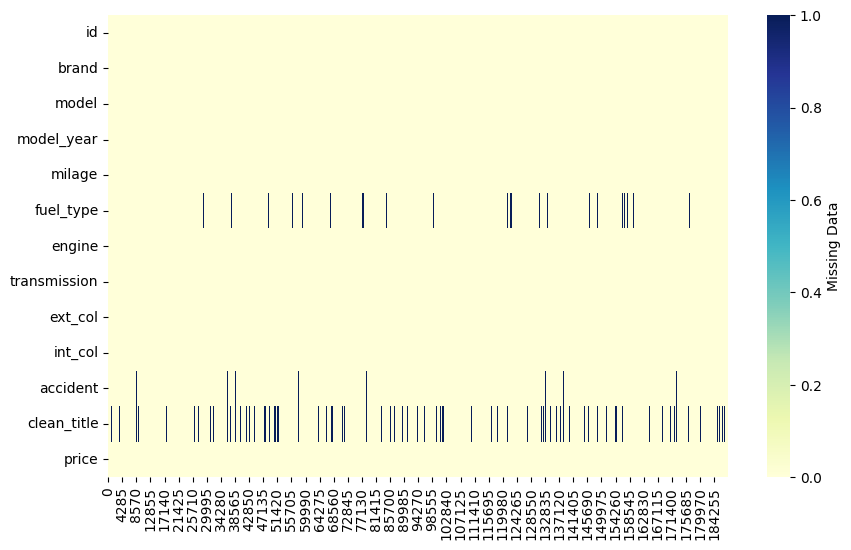

In [7]:
# Visualizing Missing Data using a seaborn heatmap.
plt.figure(figsize=(10,6))
sns.heatmap(df.isna().transpose(),
            cmap="YlGnBu",
            cbar_kws={'label': 'Missing Data'})

In [8]:
# function to fill in missing values using mode
def categorical_imputation(data, column_selected):
    # Parameter meaning
    # data => The name of the dataframe to be processed
    # column_selected => The column in which we will fill its NaN values

    # get mode value
    mode_value = data[column_selected].mode()[0]

    # change missing value
    data[column_selected] = data[column_selected].fillna(mode_value)

    # Return the dataframe after filling the missing values
    return data



In [9]:
# apply the function to 'fuel_type' column
df = categorical_imputation(data=df, column_selected='fuel_type')
df['fuel_type'].isna().sum()
# apply the function to 'accident' column
df = categorical_imputation(data=df, column_selected='accident')
df['accident'].isna().sum()
# apply the function to 'clean_title' column
df = categorical_imputation(data=df, column_selected='clean_title')
df['clean_title'].isna().sum()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     188533 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      188533 non-null  object
 11  clean_title   188533 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB


<Axes: >

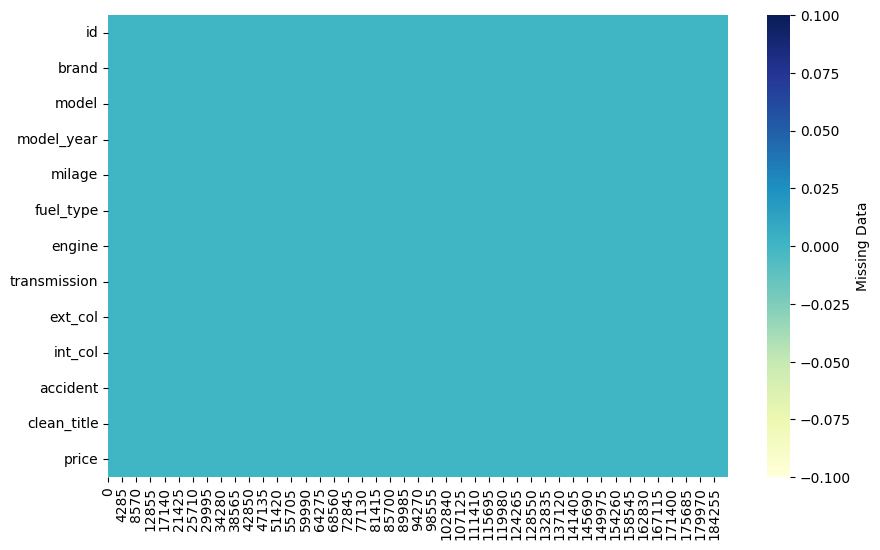

In [10]:
# Visualizing Missing Data using a seaborn heatmap.
plt.figure(figsize=(10,6))
sns.heatmap(df.isna().transpose(),
            cmap="YlGnBu",
            cbar_kws={'label': 'Missing Data'})

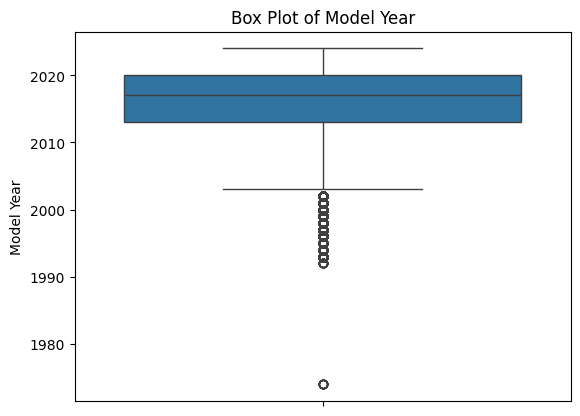

In [11]:
import matplotlib.pyplot as plt
sns.boxplot(y=df['model_year'])
plt.title('Box Plot of Model Year')
plt.ylabel('Model Year')
plt.show()

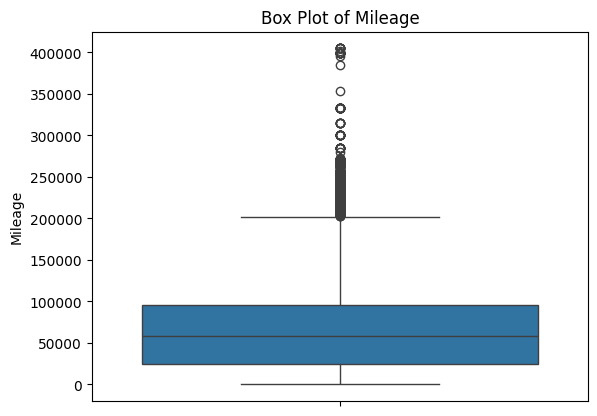

In [12]:
import matplotlib.pyplot as plt
sns.boxplot(y=df['milage'])
plt.title('Box Plot of Mileage')
plt.ylabel('Mileage')
plt.show()

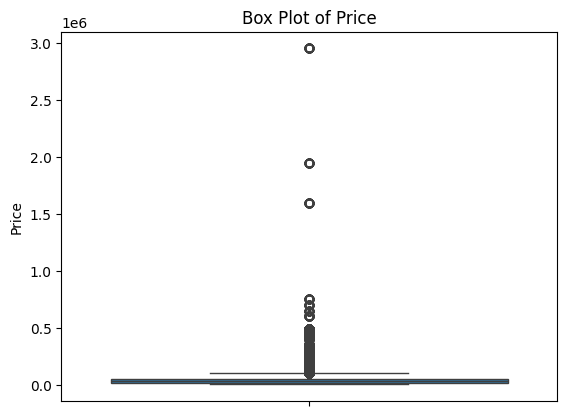

In [13]:
import matplotlib.pyplot as plt
sns.boxplot(y=df['price'])
plt.title('Box Plot of Price')
plt.ylabel('Price')
plt.show()

In [14]:
print(df[['model_year', 'milage', 'price']].describe())

          model_year         milage         price
count  188533.000000  188533.000000  1.885330e+05
mean     2015.829998   65705.295174  4.387802e+04
std         5.660967   49798.158076  7.881952e+04
min      1974.000000     100.000000  2.000000e+03
25%      2013.000000   24115.000000  1.700000e+04
50%      2017.000000   57785.000000  3.082500e+04
75%      2020.000000   95400.000000  4.990000e+04
max      2024.000000  405000.000000  2.954083e+06


In [15]:
# Function to cap outliers using IQR
def cap_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[column] = df[column].clip(lower=lower_bound, upper=upper_bound)
    return df

# Apply outlier capping to 'milage' and 'price'
df = cap_outliers_iqr(df.copy(), 'milage')
df = cap_outliers_iqr(df.copy(), 'price')

print("Descriptive statistics after outlier capping:")
print(df[['model_year', 'milage', 'price']].describe())

Descriptive statistics after outlier capping:
          model_year         milage          price
count  188533.000000  188533.000000  188533.000000
mean     2015.829998   65397.767531   37203.735537
std         5.660967   48748.009000   25835.226624
min      1974.000000     100.000000    2000.000000
25%      2013.000000   24115.000000   17000.000000
50%      2017.000000   57785.000000   30825.000000
75%      2020.000000   95400.000000   49900.000000
max      2024.000000  202327.500000   99250.000000


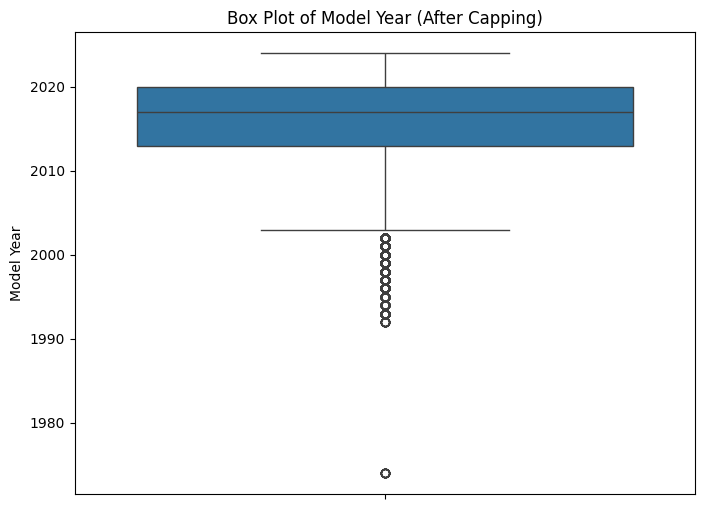

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=df['model_year'])
plt.title('Box Plot of Model Year (After Capping)')
plt.ylabel('Model Year')
plt.show()

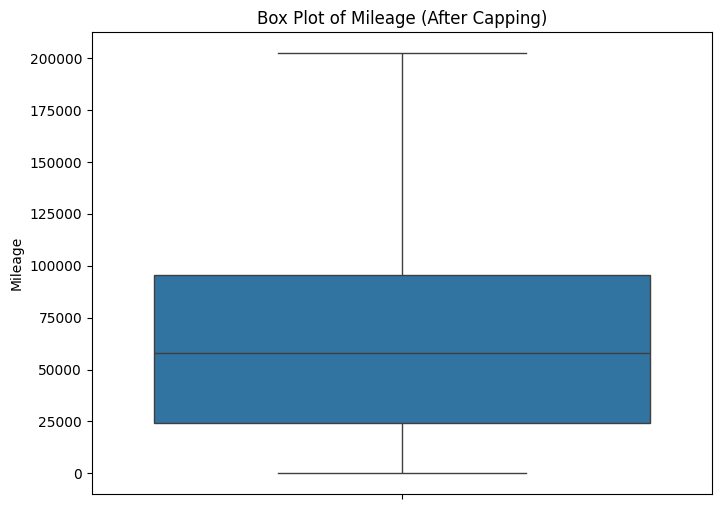

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=df['milage'])
plt.title('Box Plot of Mileage (After Capping)')
plt.ylabel('Mileage')
plt.show()

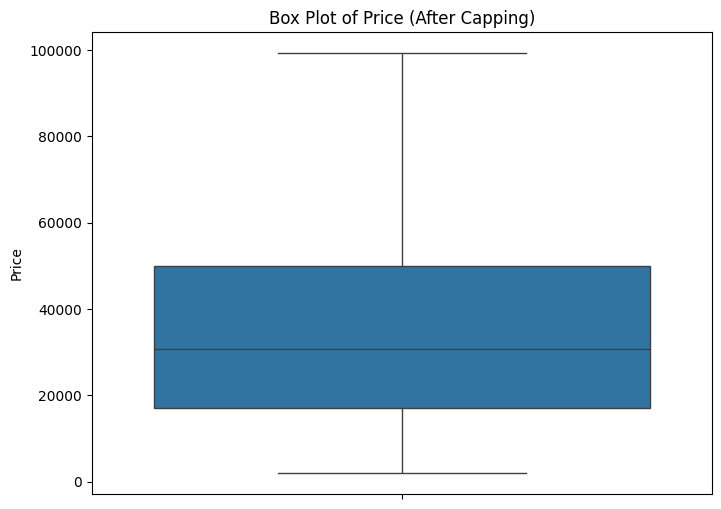

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=df['price'])
plt.title('Box Plot of Price (After Capping)')
plt.ylabel('Price')
plt.show()

In [19]:
#checking duplicated data
df.duplicated().sum()

np.int64(0)

In [20]:
# preparing the dataset using groupby
brand_agg_df = df.groupby('brand')[['price', 'milage']].mean().reset_index()

# rearranging columns
brand_agg_df = brand_agg_df[['brand', 'price', 'milage']]

brand_agg_df


,brand,price,milage
0,Acura,27043.832603,78092.682077
1,Alfa,46114.922287,31364.398827
2,Aston,62796.420168,38809.035714
3,Audi,36147.241297,59105.333333
4,BMW,38890.915433,59617.704751
5,Bentley,68341.232900,31070.873160
6,Bugatti,91307.142857,5715.000000
7,Buick,28193.098936,70188.725532
8,Cadillac,38035.443731,70132.210419
9,Chevrolet,36967.921579,68555.338200


In [21]:

# create pivot table for average price by brand and fuel type
pivot_price_brand_fuel = pd.pivot_table(
    data=df,
    index='brand',          # x-axis (Brand)
    columns='fuel_type',    # legend (Fuel Type)
    values='price',         # y-axis (Average Price)
    aggfunc='mean'
)

pivot_price_brand_fuel.head(5)


fuel_type,Diesel,E85 Flex Fuel,Gasoline,Hybrid,Plug-In Hybrid,not supported,–
brand,,,,,,,
Acura,NaN,20333.636364,26807.946942,47027.687500,NaN,NaN,24306.400000
Alfa,NaN,NaN,46114.922287,NaN,NaN,NaN,NaN
Aston,NaN,6399.000000,63394.889362,NaN,NaN,NaN,20675.000000
Audi,20938.138211,22678.117808,34380.490966,48226.902533,58950.000000,NaN,16962.500000
BMW,36251.916667,23441.666667,38289.178920,59002.682415,49308.207207,NaN,45566.666667


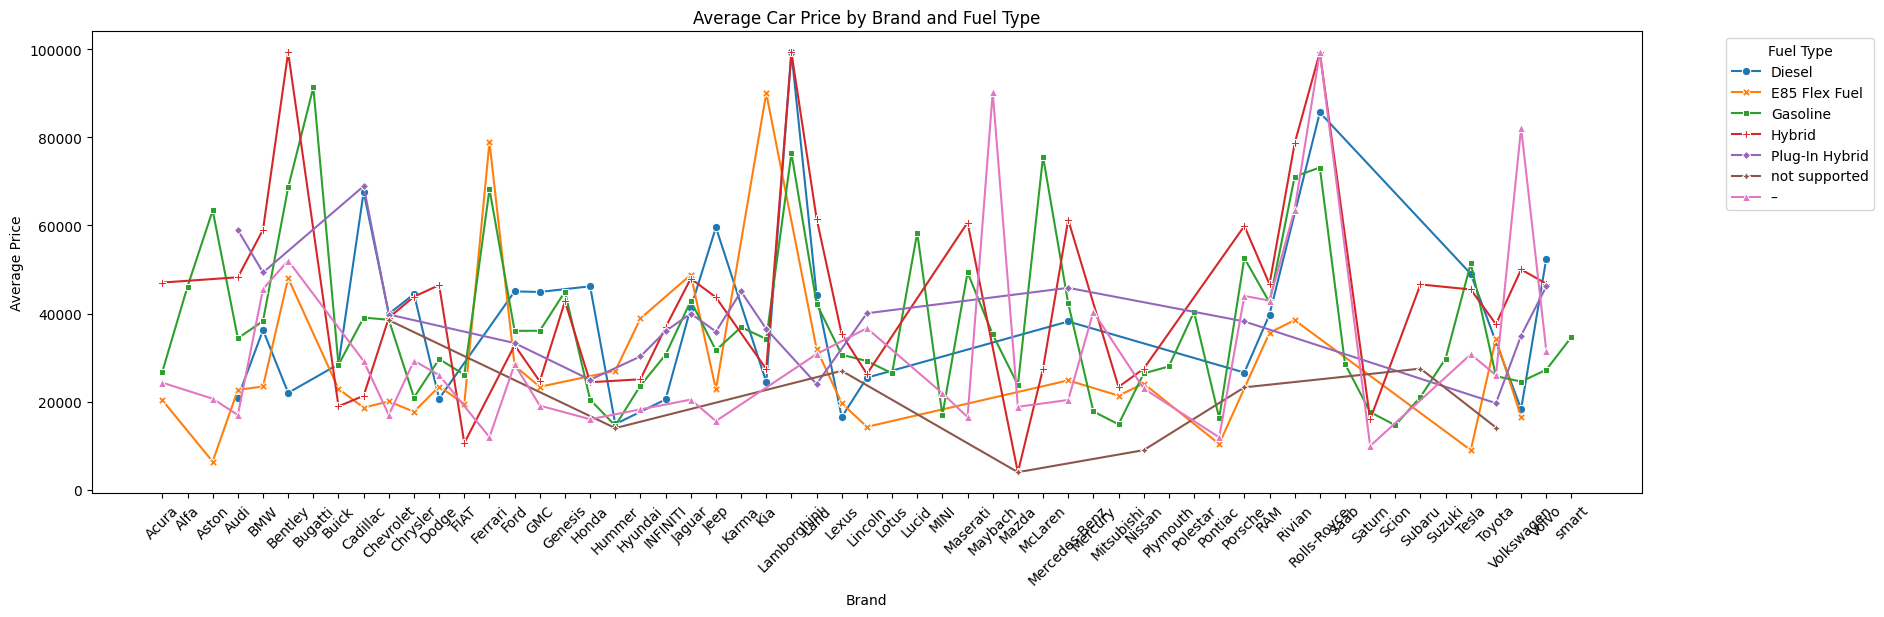

In [22]:
# visualizing average price by brand and fuel type
plt.figure(figsize=(20,6))
plt.title('Average Car Price by Brand and Fuel Type')

sns.lineplot(
    data=pivot_price_brand_fuel,
    dashes=False,
    markers=True
)

plt.xlabel('Brand')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.legend(title='Fuel Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


In [23]:
df.sample(5)

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
138153,138153,Lexus,GX 460 Luxury,2017,123815.0,Gasoline,4.6L V8 32V MPFI DOHC,5-Speed Automatic,Caviar,Rioja Red,None reported,Yes,23999
80252,80252,Ford,F-150 Platinum,2017,125000.0,E85 Flex Fuel,395.0HP 5.0L 8 Cylinder Engine Flex Fuel Capab...,A/T,Black,Black,None reported,Yes,24000
134781,134781,GMC,Acadia SLT-1,2011,116226.0,Gasoline,288.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,7900
92256,92256,Dodge,Ram 1500 SLT Mega Cab,2006,201509.0,Gasoline,345.0HP 5.7L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Gray,At least 1 accident or damage reported,Yes,12500
31055,31055,Audi,e-tron Prestige,2022,17000.0,Gasoline,355.0HP Electric Motor Electric Fuel System,A/T,White,Beige,None reported,Yes,71000


In [24]:
feature_names = ['model_year', 'milage', 'price']


In [25]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd

def get_knn(df, n, k, metric):
    """
    Display k nearest neighbors using a selected distance metric

    Parameters:
    df      : Pandas DataFrame
    n       : index of the reference data point
    k       : number of nearest neighbors
    metric  : distance metric ('euclidean' or 'manhattan')
    """

    nbrs = NearestNeighbors(
        n_neighbors=k,
        metric=metric,
        algorithm='brute'
    )

    # fit model
    nbrs.fit(df[feature_names])

    # find neighbors
    distances, indices = nbrs.kneighbors(
        [df.iloc[n][feature_names]],
        return_distance=True
    )

    # combine results
    df_result = pd.concat(
        [
            df.iloc[indices[0]],
            pd.DataFrame(distances.T, index=indices[0], columns=['distance'])
        ],
        axis=1
    )

    return df_result


In [26]:
# euclidean metric - unscaled data
knn_euclidean_unscaled = get_knn(df, n=1, k=50, metric='euclidean')
knn_euclidean_unscaled.head()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,distance
1,1,Lincoln,LS V8,2002,143250.0,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999,0.000000
93601,93601,Cadillac,CTS Base,2009,143250.0,Gasoline,255.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed M/T,Gray,Black,At least 1 accident or damage reported,Yes,5000,7.071068
49448,49448,Land,Rover Range Rover Sport Supercharged,2011,143250.0,Gasoline,510.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,A/T,White,Beige,None reported,Yes,4999,9.000000
3006,3006,Lexus,GS 350 Base,2006,143346.0,Gasoline,215.0HP 3.2L V6 Cylinder Engine Gasoline Fuel,A/T,Red,Black,At least 1 accident or damage reported,Yes,5000,96.088501
97403,97403,Nissan,Altima 2.5 S,2014,143250.0,Gasoline,175.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Silver,Gray,At least 1 accident or damage reported,Yes,4900,99.724621


In [27]:
# manhattan metric - unscaled data
knn_manhattan_unscaled = get_knn(df, n=1, k=50, metric='manhattan')
knn_manhattan_unscaled.head()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,distance
1,1,Lincoln,LS V8,2002,143250.0,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999,0.0
93601,93601,Cadillac,CTS Base,2009,143250.0,Gasoline,255.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed M/T,Gray,Black,At least 1 accident or damage reported,Yes,5000,8.0
49448,49448,Land,Rover Range Rover Sport Supercharged,2011,143250.0,Gasoline,510.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,A/T,White,Beige,None reported,Yes,4999,9.0
3006,3006,Lexus,GS 350 Base,2006,143346.0,Gasoline,215.0HP 3.2L V6 Cylinder Engine Gasoline Fuel,A/T,Red,Black,At least 1 accident or damage reported,Yes,5000,101.0
97403,97403,Nissan,Altima 2.5 S,2014,143250.0,Gasoline,175.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Silver,Gray,At least 1 accident or damage reported,Yes,4900,111.0


In [28]:
from sklearn.preprocessing import MaxAbsScaler

# fit scaler
transformer_mas = MaxAbsScaler().fit(df[feature_names].to_numpy())

# create scaled dataframe
df_scaled = df.copy()
df_scaled.loc[:, feature_names] = transformer_mas.transform(
    df[feature_names].to_numpy()
)
df_scaled.sample(5)

/tmp/ipykernel_1038/686251528.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.99160079 0.98913043 0.98913043 ... 0.99851779 0.99901186 0.99604743]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = transformer_mas.transform(
/tmp/ipykernel_1038/686251528.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.04231738 0.05036776 0.14005038 ... 0.87556675 0.85541562 0.29214106]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = transformer_mas.transform(


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
155422,155422,Ford,Mustang EcoBoost Premium,0.997530,0.348835,Gasoline,310.0HP 2.3L 4 Cylinder Engine Gasoline Fuel,A/T,White,Black,None reported,Yes,0.381854
74378,74378,Lexus,IS 300 Base,0.997036,0.079080,Gasoline,260.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Gray,Red,None reported,Yes,0.675063
12784,12784,INFINITI,G37 Sport,0.989625,0.609161,Gasoline,328.0HP 3.7L V6 Cylinder Engine Gasoline Fuel,5-Speed M/T,Red,Black,None reported,Yes,0.120907
151453,151453,Buick,Enclave Leather,0.995059,0.840222,Gasoline,288.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Silver,Red,None reported,Yes,0.267003
97345,97345,Ford,Mustang GT Premium,0.995059,0.219738,Gasoline,435.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,6-Speed M/T,Blue,Black,None reported,Yes,0.438287


In [29]:
get_knn(df_scaled, 1, 10, 'euclidean')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,distance
1,1,Lincoln,LS V8,0.989130,0.708011,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,0.050368,0.000000
187144,187144,Toyota,Sequoia SR5,0.990119,0.708727,Gasoline,273.0HP 4.7L 8 Cylinder Engine Gasoline Fuel,A/T,Black,Gray,None reported,Yes,0.050378,0.001221
182661,182661,Jeep,Wrangler SE,0.989625,0.709740,Gasoline,150.0HP 2.4L 4 Cylinder Engine Gasoline Fuel,5-Speed M/T,Black,Gray,None reported,Yes,0.050378,0.001799
3006,3006,Lexus,GS 350 Base,0.991107,0.708485,Gasoline,215.0HP 3.2L V6 Cylinder Engine Gasoline Fuel,A/T,Red,Black,At least 1 accident or damage reported,Yes,0.050378,0.002032
116054,116054,Chevrolet,Silverado 2500 LT H/D Extended Cab,0.991107,0.708702,Diesel,325.0HP 6.0L 8 Cylinder Engine Diesel Fuel,A/T,Black,Black,None reported,Yes,0.050378,0.002094
162819,162819,Chevrolet,Corvette Base,0.991107,0.707244,Gasoline,400.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,6-Speed A/T,Red,Beige,At least 1 accident or damage reported,Yes,0.050378,0.002120
29835,29835,Hummer,H2 Base,0.990613,0.706775,Gasoline,316.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Black,At least 1 accident or damage reported,Yes,0.049370,0.002172
165114,165114,Porsche,Boxster S,0.990613,0.706775,Gasoline,280.0HP 3.2L Flat 6 Cylinder Engine Gasoline Fuel,6-Speed M/T,Black,Gray,None reported,Yes,0.049370,0.002172
107958,107958,Ford,Mustang Premium,0.990613,0.708011,Gasoline,210.0HP 4.0L V6 Cylinder Engine Gasoline Fuel,A/T,White,Gray,None reported,Yes,0.052383,0.002502
121642,121642,Hummer,H2 Base,0.990119,0.706775,Gasoline,325.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Black,None reported,Yes,0.048363,0.002554


In [30]:
get_knn(df_scaled, 1, 10, 'manhattan')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,distance
1,1,Lincoln,LS V8,0.989130,0.708011,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,0.050368,0.000000
187144,187144,Toyota,Sequoia SR5,0.990119,0.708727,Gasoline,273.0HP 4.7L 8 Cylinder Engine Gasoline Fuel,A/T,Black,Gray,None reported,Yes,0.050378,0.001715
182661,182661,Jeep,Wrangler SE,0.989625,0.709740,Gasoline,150.0HP 2.4L 4 Cylinder Engine Gasoline Fuel,5-Speed M/T,Black,Gray,None reported,Yes,0.050378,0.002234
3006,3006,Lexus,GS 350 Base,0.991107,0.708485,Gasoline,215.0HP 3.2L V6 Cylinder Engine Gasoline Fuel,A/T,Red,Black,At least 1 accident or damage reported,Yes,0.050378,0.002461
116054,116054,Chevrolet,Silverado 2500 LT H/D Extended Cab,0.991107,0.708702,Diesel,325.0HP 6.0L 8 Cylinder Engine Diesel Fuel,A/T,Black,Black,None reported,Yes,0.050378,0.002678
162819,162819,Chevrolet,Corvette Base,0.991107,0.707244,Gasoline,400.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,6-Speed A/T,Red,Beige,At least 1 accident or damage reported,Yes,0.050378,0.002752
93601,93601,Cadillac,CTS Base,0.992589,0.708011,Gasoline,255.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed M/T,Gray,Black,At least 1 accident or damage reported,Yes,0.050378,0.003469
107958,107958,Ford,Mustang Premium,0.990613,0.708011,Gasoline,210.0HP 4.0L V6 Cylinder Engine Gasoline Fuel,A/T,White,Gray,None reported,Yes,0.052383,0.003497
29835,29835,Hummer,H2 Base,0.990613,0.706775,Gasoline,316.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Black,At least 1 accident or damage reported,Yes,0.049370,0.003715
165114,165114,Porsche,Boxster S,0.990613,0.706775,Gasoline,280.0HP 3.2L Flat 6 Cylinder Engine Gasoline Fuel,6-Speed M/T,Black,Gray,None reported,Yes,0.049370,0.003715


In [31]:
df['clean_title'].value_counts()


,count
clean_title,
Yes,188533


In [32]:
df_numerical = ['model_year', 'milage']
X = df[df_numerical]
y = df['price']



In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

beforeScaling_lr = LinearRegression()
beforeScaling_lr.fit(X_train, y_train)

y_pred = beforeScaling_lr.predict(X_test)

print("MAE =", mean_absolute_error(y_test, y_pred))
print("R² =", r2_score(y_test, y_pred))



MAE = 14606.614749420443
R² = 0.4538132197241037


In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)



In [36]:
afterScaling_lr = LinearRegression()
afterScaling_lr.fit(X_train_std, y_train)

y_pred_std = afterScaling_lr.predict(X_test_std)

print("MAE =", mean_absolute_error(y_test, y_pred_std))
print("R² =", r2_score(y_test, y_pred_std))


MAE = 14606.61474942045
R² = 0.4538132197241034


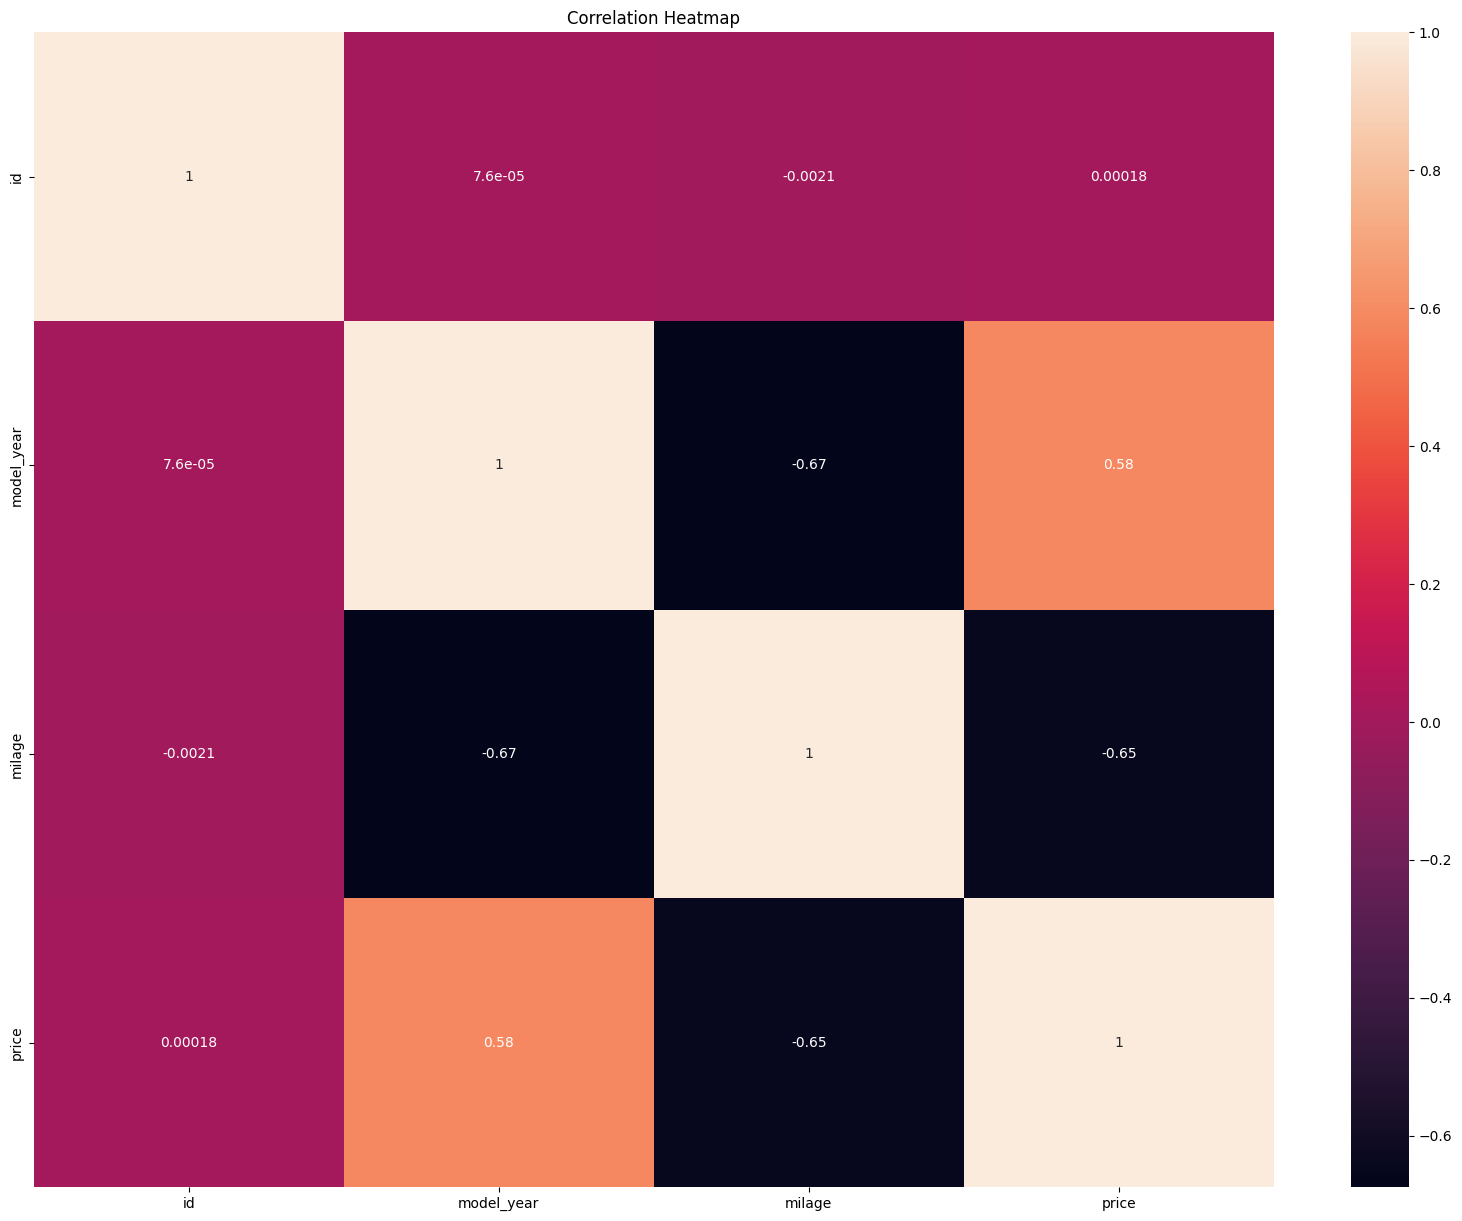

In [37]:
df_numeric = df.select_dtypes(include=['int64', 'float64'])


plt.figure(figsize=(20,15))
heatmap = sns.heatmap(df_numeric.corr(), annot=True)
heatmap.set_title('Correlation Heatmap', fontdict={'fontsize':12})
plt.show()


In [38]:
df_numeric.corr()['price'].sort_values()


,price
milage,-0.647345
id,0.000184
model_year,0.583629
price,1.000000


In [39]:
# positively correlated
df_numeric.corr()['price'][df_numeric.corr()['price'] > 0.1]

# negatively correlated
df_numeric.corr()['price'][df_numeric.corr()['price'] < -0.1]


,price
milage,-0.647345


In [40]:
outliers = df_numeric[['model_year', 'milage', 'price']]


In [41]:
!pip install pyod

In [42]:
from pyod.models.knn import KNN

model = KNN()
model.fit(outliers)

outliers['is_outlier'] = model.predict(outliers) == 1
outliers_knn = outliers['is_outlier'].sum()

print("Number of Anomalies:", outliers_knn)

Number of Anomalies: 14639


In [43]:
outlier_keys = list(outliers[outliers['is_outlier'] == 1].index)
df = df.drop(outlier_keys)

df.shape


(173894, 13)

In [44]:
df['clean_title'].value_counts() / df.shape[0] * 100


,count
clean_title,
Yes,100.0


In [45]:
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

# encode target
df['clean_title_encoded'] = df['clean_title'].map({'Yes': 1, 'No': 0})

# select numerical features
features = df[['model_year', 'milage', 'price']]
target = df['clean_title_encoded']

# train-test split
features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=0.2, random_state=42, stratify=target
)


In [46]:
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_upsampled = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)

    features_upsampled, target_upsampled = shuffle(
        features_upsampled, target_upsampled, random_state=42
    )

    return features_upsampled, target_upsampled


In [47]:
target_train.value_counts()


,count
clean_title_encoded,
1,139115


In [48]:
features_upsampled, target_upsampled = upsample(features_train, target_train, 4)


In [49]:
target_upsampled.value_counts()


,count
clean_title_encoded,
1,556460


In [50]:
def downsample(features, target, fraction):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_downsampled = pd.concat(
        [features_zeros.sample(frac=fraction, random_state=42)] + [features_ones]
    )
    target_downsampled = pd.concat(
        [target_zeros.sample(frac=fraction, random_state=42)] + [target_ones]
    )

    features_downsampled, target_downsampled = shuffle(
        features_downsampled, target_downsampled, random_state=42
    )

    return features_downsampled, target_downsampled


In [51]:
target_train.value_counts()


,count
clean_title_encoded,
1,139115


In [52]:
features_downsampled, target_downsampled = downsample(features_train, target_train, 0.3)


In [53]:
target_downsampled.value_counts()


,count
clean_title_encoded,
1,139115


In [54]:
df.head()

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,clean_title_encoded
0,0,MINI,Cooper S Base,2007,202327.5,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200,1
1,1,Lincoln,LS V8,2002,143250.0,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999,1
2,2,Chevrolet,Silverado 2500 LT,2002,136731.0,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900,1
3,3,Genesis,G90 5.0 Ultimate,2017,19500.0,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000,1
4,4,Mercedes-Benz,Metris Base,2021,7388.0,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500,1


In [55]:
# define nominal categorical features
df_categorical = [
    'brand',
    'model',
    'fuel_type',
    'engine',
    'transmission',
    'ext_col',
    'int_col',
    'accident',
    'clean_title'
]

# apply one-hot encoding
df = pd.get_dummies(df, columns=df_categorical, drop_first=True)


In [56]:
# preview encoded dataset
df.head()


,id,model_year,milage,price,clean_title_encoded,brand_Alfa,brand_Aston,brand_Audi,brand_BMW,brand_Bentley,...,int_col_Tupelo,int_col_Very Light Cashmere,int_col_WHITE,int_col_Walnut,int_col_Whisper Beige,int_col_White,int_col_White / Brown,int_col_Yellow,int_col_–,accident_None reported
0,0,2007,202327.5,4200,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,1,2002,143250.0,4999,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2,2002,136731.0,13900,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,3,2017,19500.0,45000,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,4,2021,7388.0,97500,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [57]:
from sklearn.model_selection import train_test_split
df_train_valid, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['clean_title_encoded']
)
df_train, df_valid = train_test_split(
    df_train_valid,
    test_size=0.25,
    random_state=42,
    stratify=df_train_valid['clean_title_encoded']
)
features_train = df_train.drop('clean_title_encoded', axis=1)
target_train = df_train['clean_title_encoded']
features_valid = df_valid.drop('clean_title_encoded', axis=1)
target_valid = df_valid['clean_title_encoded']
features_test = df_test.drop('clean_title_encoded', axis=1)
target_test = df_test['clean_title_encoded']


In [58]:
print(features_train.shape)
print(target_train.shape)

(104336, 3603)
(104336,)


In [59]:
print(features_valid.shape)
print(target_valid.shape)

(34779, 3603)
(34779,)


In [60]:
print(features_test.shape)
print(target_test.shape)

(34779, 3603)
(34779,)


In [61]:
df.head(5)

,id,model_year,milage,price,clean_title_encoded,brand_Alfa,brand_Aston,brand_Audi,brand_BMW,brand_Bentley,...,int_col_Tupelo,int_col_Very Light Cashmere,int_col_WHITE,int_col_Walnut,int_col_Whisper Beige,int_col_White,int_col_White / Brown,int_col_Yellow,int_col_–,accident_None reported
0,0,2007,202327.5,4200,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,1,2002,143250.0,4999,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2,2002,136731.0,13900,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,3,2017,19500.0,45000,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,4,2021,7388.0,97500,1,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


feature seection


In [62]:
#  #select numeric columns only
# df_numeric = df.select_dtypes(include=['int64', 'float64'])

# # calculate Pearson correlation matrix
# correlation_matrix = df_numeric.corr()

# # correlation of all features with price
# price_correlation = correlation_matrix['price'].sort_values(ascending=False)

# print(price_correlation)

# # features with correlation > 0.1 or < -0.1
# important_features = price_correlation[
#     (price_correlation > 0.1) | (price_correlation < -0.1)
# ]

# print(important_features)

In [63]:
# import pandas as pd
# from sklearn.feature_selection import SelectKBest, f_regression


# # features (all columns except target)
# X = df.drop('price', axis=1)

# # target variable
# y = df['price']

# # apply SelectKBest using ANOVA F-value
# selector = SelectKBest(score_func=f_regression, k='all')
# selector.fit(X, y)


# # create feature score dataframe
# feature_scores = pd.DataFrame({
#     'Feature': X.columns,
#     'Score': selector.scores_
# })

# # sort features by score
# feature_scores = feature_scores.sort_values(by='Score', ascending=False)

# # display top features
# feature_scores.head(20)


In [64]:
# Define features and target

X = df[["milage", "model_year"]]
y = df["price"]

In [65]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [66]:
from sklearn.linear_model import LinearRegression

# Initialize Linear Regression model
model = LinearRegression(
    fit_intercept=True,   # suitable for price prediction
    n_jobs=-1             # use all CPU cores (more efficient for large data)
)


In [67]:
from sklearn.feature_selection import RFE

# Perform RFE to select the top 5 most important features
rfe = RFE(
    estimator=model,
    n_features_to_select=2, # Changed from 5 to 2, as X_train only has 2 features
    step=1        # remove one feature per iteration (most accurate)
)

# Fit RFE on training data
rfe.fit(X_train, y_train)

RFE(estimator=LinearRegression(n_jobs=-1), n_features_to_select=2)

In [68]:
# Identify and print the selected features
selected_features = X_train.columns[rfe.support_]

print("Selected Features:")
for feature in selected_features:
    print("- ", feature)

Selected Features:
-  milage
-  model_year


### Train the model with selected features

In [69]:
# Transform X_train and X_test to include only the selected features
X_train_rfe = rfe.transform(X_train)
X_test_rfe = rfe.transform(X_test)

# Train the model with the RFE-selected features
model.fit(X_train_rfe, y_train)

# Make predictions on the transformed test set
y_pred_rfe = model.predict(X_test_rfe)

# Evaluate the model's performance
from sklearn.metrics import mean_absolute_error, r2_score

print("Model performance with selected features:")
print("MAE =", mean_absolute_error(y_test, y_pred_rfe))
print("R² =", r2_score(y_test, y_pred_rfe))

Model performance with selected features:
MAE = 13527.312412697527
R² = 0.5023836322203248


### Making Predictions and Evaluating the Model (MSE)

Predictions are made on the test set using the trained model. The model's performance is further evaluated by calculating the Mean Squared Error (MSE), which gives another indication of the model's accuracy.

In [70]:
from sklearn.metrics import mean_squared_error

# Calculate the Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred_rfe)
print("Mean Squared Error:", mse)

Mean Squared Error: 323570406.22233635


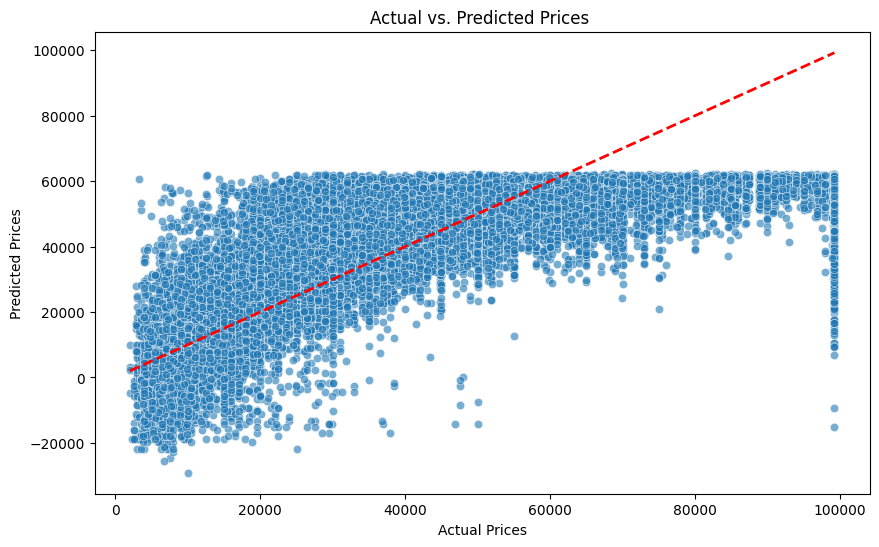

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred_rfe, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual vs. Predicted Prices ')
plt.show()

In [72]:
import joblib

# Save your trained model
joblib.dump(model, "model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [73]:
from google.colab import files

files.download("model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
import joblib

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [75]:
from google.colab import files

files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>